In [1]:
# Solving the committor equation via neural network representation
import numpy as np
import math
import csv
import matplotlib.pyplot as plt
import torch

# torch.set_default_tensor_type(torch.DoubleTensor)
# torch.set_default_dtype(torch.float64)
plt.rcParams.update({'font.size': 14})

# fix random seeds for reproducibility
torch.manual_seed(0)
np.random.seed(0)

# A variational neural network-based solver for the committor problem
Ref.: 
[1] Qianxiao Li, Bo Lin,  Weiqing Ren, "*Computing committor functions for the study of rare events using deep learning*", J. Chem. Phys. 151, 054112 (2019)
https://pubs.aip.org/aip/jcp/article-abstract/151/5/054112/198621/Computing-committor-functions-for-the-study-of

The committor problem for the overdamped Langevin dynamics
$$ dX_t = - \nabla V(X_t)dt + \sqrt{2\beta^{-1}}dW_t,\quad X_t\in\mathbb{R}^d,$$
is the following. Let $A$ and $B$ be disjoint regions surrounding metastable states, e.g. neighborhoods of two local minima of $V(x)$. The committor function $q(x)$ is the probability that the process starting at $x$ will hit first set $B$ rather than set $A$. The committor is the solution to the following boundary value problem for the backward Kolmogorov equation: 
$$\nabla\cdot\left(e^{-\beta V(x)}\nabla q(x)\right) = 0,\quad x\in\Omega_{AB}:=\mathbb{R}^d\backslash (A\cup B),$$
$$ q(\partial A) = 0,\quad q(\partial B) = 1.$$

The committor problem is linear, self-adjoint, and the function $e^{-\beta V(x)}$ is positive.
Therefore, the committor problem has the following variational formulation:
$q(x)$ is the minimizer of the Dirichlet form 
$$I[u]: = \int_{\Omega_{AB}} e^{-\beta V(x)}\|\nabla u(x)\|^2dx$$
among all $u\in C^2(\Omega_{AB})\cap C(\bar{\Omega}_{AB})$ satisfying the boundary conditions $u(\partial A) = 0$, $u(\partial B) = 1$.

This fact inspires the following optimization problem for the committor. We propose a solution model
$$ q(x) = F(x,\theta): = (1-\chi_{A}(x))\left((1-\chi_B(x))N(x;\theta) + \chi_B(x)\right)$$
where $\chi_A(x)$ and $\chi_B(x)$ are smoothed indicator functions of $A$ and $B$, respectively, and $N(x;\theta)$ is a neural network function, where $\theta$ is the vector of all parameters of the neural network. Note that $F(x,\theta)$ is designed to satisfy the boundary conditions. Then we optimize $I[F(x;\theta)]$ with respect to $\theta$. Then the resulting $F(x;\theta)$ is the solution to the committor problem.

In this code, we apply this method to a 2D committor problem where $V(x)$ is the face potential, and the sets $A$ and $B$ are neighborhoods of the minima located in the "eyes". 

Since this is a 2D problem, we compare its solution to the finite element solution. We use three error metrics:

* Mean Absolute Error (MAE):
$${\rm MAE} = \frac{1}{N_{\sf train}}\sum_{j=1}^{N_{\sf train}}|q_{\sf NN}(x_j) - q_{\sf FEM}(x_j)|;$$
* Root Mean Squared Error (RMSE):
$${\rm RMSE} = \left[\frac{1}{N_{\sf train}}\sum_{j=1}^{N_{\sf train}}|q_{\sf NN}(x_j) - q_{\sf FEM}(x_j)|^2\right]^{1/2};$$
* Weighted Absolute Error (WAE): $${\rm WAE} = \sum_{j=1}^{N_{\sf train}}w(x_j)|q_{\sf NN}(x_j) - q_{\sf FEM}(x_j)|,$$ where $$w(x) = \frac{e^{-\beta V(x)}q_{\sf FEM}(x)(1-q_{\sf FEM}(x))}{\sum_{j=1}^{N_{\sf train}}e^{-\beta V(y_j)}q_{\sf FEM}(y_j)(1-q_{\sf FEM}(y_j))}$$ is the probability density of transition trajectories [2], [3];


Refs.: 
[2] Weinan E, Eric Vanden-Eijnden, "*Towards the theory of transition paths*", Journal of Statistical Physics, 123, 503--523 (2006), https://link.springer.com/article/10.1007/s10955-005-9003-9

[3] Jiaxin Yuan, Amar Shah, Channing Bentz, Maria Cameron, "*Optimal control for sampling the transition path process and estimating rates*", Communications in Nonlinear Science and Numerical Simulation, Volume 129, February 2024, 107701, 
https://www.sciencedirect.com/science/article/pii/S1007570423006226?casa_token=2DfEtNNRr_IAAAAA:AzGAlv091e36p9nCumWP7NPWAQv15JhoTMUJ4JkF-m3phE1N1_9WIXz58ajxdKO3iCCePGlT7t4


In [2]:
beta = torch.tensor(0.5) # inverse temperature

# The numpy-type potential function
def Vpot(xy):
    xa=-3
    ya=3
    xb=0 
    yb=4.5
    x = xy[:,0]
    y = xy[:,1]
    f=(1-x)**2+(y-0.25*x**2)**2+1
    g1=1-np.exp(-0.125*((x-xa)**2+(y-ya)**2))
    g2=1-np.exp(-0.25*(((x-xb)**2+(y-yb)**2)))
    g3=1.2-np.exp(-2*((x+0)**2+(y-2)**2))
    g4=1+np.exp(-2*(x+1.5)**2-(y-3.5)**2-(x+1)*(y-3.5))
    v = f*g1*g2*g3*g4
    return v


In [3]:
# The torch tensor-type potential function
def Vpot_torch(x,y):
    xa=torch.tensor([-3])
    ya=torch.tensor([3])
    xb=torch.tensor([0]) 
    yb=torch.tensor([4.5])

    f=(1-x).pow(2)+(y-0.25*x.pow(2)).pow(2)+1
    g1=1-torch.exp(-0.125*((x-xa).pow(2)+(y-ya).pow(2)))
    g2=1-torch.exp(-0.25*(((x-xb).pow(2)+(y-yb).pow(2))))
    g3=1.2-torch.exp(-2*((x+0).pow(2)+(y-2).pow(2)))
    g4=1+torch.exp(-2*(x+1.5).pow(2)-(y-3.5).pow(2)-(x+1)*(y-3.5))

    v = f*g1*g2*g3*g4
    return v  

In [4]:
# define grid points
nx,ny= (100,100)
nxy = nx*ny
xmin = -4.5
xmax = 4
ymin = -3
ymax = 6
x1 = np.linspace(xmin,xmax,nx)
y1 = np.linspace(ymin,ymax,ny)
x_grid, y_grid = np.meshgrid(x1,y1)   # arrays of shape (ny,nx)
x_vec = np.reshape(x_grid, (nxy,1))
y_vec = np.reshape(y_grid, (nxy,1))

xy = np.concatenate((x_vec,y_vec),axis=1)
v = Vpot(xy)
v_grid = np.reshape(v,(ny,nx))

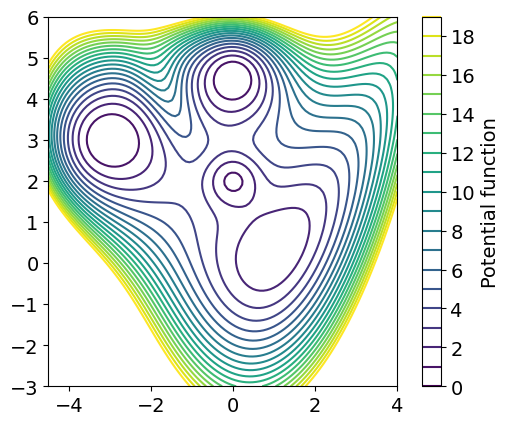

In [5]:
# plot face potential
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20))
plt.colorbar(label="Potential function", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)


## The neural network function with layer normalization (LN):
$$ N(x) = {\rm Sigmoid}(W3@\tanh({\rm LN}(W2@\tanh({\rm LN}(W1@\tanh({\rm LN}(W0@x+b0))+b1))+b2))+b3)$$

The solution model: 
$$F(x) = (1-\chi_a(x))*((1-\chi_b(x))*N(x) + \chi_b(x))$$

### Layer Normalization

**What it is.** Layer normalization (Ba, Kiros & Hinton, 2016) rescales the activations of a layer *for each individual input sample*. Let $\mathbf{h} = (h_1, \dots, h_d)$ be the vector of pre-activations (or activations) of one layer for one sample. LayerNorm first computes the mean and variance **across the $d$ features**:

$$
\mu = \frac{1}{d}\sum_{i=1}^{d} h_i, \qquad
\sigma^2 = \frac{1}{d}\sum_{i=1}^{d} (h_i - \mu)^2 ,
$$

then normalizes and applies a learnable affine map:

$$
\mathrm{LN}(\mathbf{h})_i = \gamma_i \, \frac{h_i - \mu}{\sqrt{\sigma^2 + \varepsilon}} + \beta_i .
$$

Here $\gamma, \beta \in \mathbb{R}^d$ are trainable parameters, and $\varepsilon$ is a small constant for numerical stability. Because of $\gamma$ and $\beta$, the network can undo the normalization if that helps it.

**What it is for.**

- **Stable, faster training.** As the weights in earlier layers change during training, the scale and offset of each layer's inputs keep shifting. Normalizing keeps activations at a controlled scale. This reduces exploding or vanishing signals, allows larger learning rates, and makes the loss landscape better conditioned.
- **Independence from the batch.** Unlike *batch normalization*, which averages each feature over the samples in a mini-batch, LayerNorm averages over the features of a single sample. So it:
  - works the same way during training and inference (no running averages needed),
  - works with batch size 1 and variable-length sequences,
  - fits naturally into recurrent networks and Transformers. In Transformers, LayerNorm is a standard part of every block.

**Batch norm vs. layer norm, for a data matrix $X \in \mathbb{R}^{N \times d}$ (batch × features):**

| | normalizes over | statistics depend on |
|---|---|---|
| BatchNorm | the batch dimension $N$ (per feature) | the other samples in the batch |
| LayerNorm | the feature dimension $d$ (per sample) | only the sample itself |

In PyTorch: `torch.nn.LayerNorm(d)`.

In [6]:
class CommittorModelNN(torch.nn.Module):

    def __init__(self,in_size, hidden_size, out_size):
        super(CommittorModelNN, self).__init__()

        self.linear0 = torch.nn.Linear(in_size, hidden_size)
        self.norm0 = torch.nn.LayerNorm(hidden_size)
        self.activation0 = torch.nn.Tanh()
        self.linear1 = torch.nn.Linear(hidden_size, hidden_size)
        self.norm1 = torch.nn.LayerNorm(hidden_size)
        self.activation1 = torch.nn.Tanh()
        self.linear2 = torch.nn.Linear(hidden_size, hidden_size)
        self.norm2 = torch.nn.LayerNorm(hidden_size)
        self.activation2 = torch.nn.Tanh()
        self.linear3 = torch.nn.Linear(hidden_size, out_size)
        self.sigmoid = torch.nn.Sigmoid()

    def forward(self,x,a,b,ra,rb,ea,eb,fac):
        # neural network part N(x)
        q = self.activation0(self.norm0(self.linear0(x)))
        q = self.activation1(self.norm1(self.linear1(q)))
        q = self.activation2(self.norm2(self.linear2(q)))
        q = self.sigmoid(self.linear3(q))
        # smoothed indicator functions of A and B
        aux0 = ((x-a).pow(2)).sum(dim=1,keepdim=True) - (ra+ea).pow(2)
        aux1 = ((x-b).pow(2)).sum(dim=1,keepdim=True) - (rb+eb).pow(2)
        chia = 0.5-0.5*torch.tanh(fac*aux0)
        chib = 0.5-0.5*torch.tanh(fac*aux1)
        # solution model satisfying the boundary conditions
        q = (1-chia)*((1-chib)*q+chib)
        return q

# define sets A and B (centers are float tensors to match the float32 data)
minimum_a = np.array([-3.,3.])
a = torch.tensor(minimum_a, dtype=torch.float32)
minimum_b = np.array([0.,4.5])
b = torch.tensor(minimum_b, dtype=torch.float32)

ra = torch.tensor(0.5)
rb = torch.tensor(0.5)
fac = torch.tensor(100.)
ea = 2./(ra*fac)
eb = 2./(rb*fac)
# define the dimensions for the neural network
in_size = 2 # the dimension of input data points
hidden_size = 25 # the number of neurons in the hidden layer
out_size = 1 # the output size of the neural network

# test neural network
qmodel = CommittorModelNN(in_size, hidden_size, out_size)
print(qmodel)

CommittorModelNN(
  (linear0): Linear(in_features=2, out_features=25, bias=True)
  (norm0): LayerNorm((25,), eps=1e-05, elementwise_affine=True, bias=True)
  (activation0): Tanh()
  (linear1): Linear(in_features=25, out_features=25, bias=True)
  (norm1): LayerNorm((25,), eps=1e-05, elementwise_affine=True, bias=True)
  (activation1): Tanh()
  (linear2): Linear(in_features=25, out_features=25, bias=True)
  (norm2): LayerNorm((25,), eps=1e-05, elementwise_affine=True, bias=True)
  (activation2): Tanh()
  (linear3): Linear(in_features=25, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [18]:
# import training points
ftraindata_name = "Face_DeltaNet.npz"
data = np.load(ftraindata_name)
xytrain = data['delta_net']
Ndata = np.size(xytrain,axis=0)
print(xytrain[0:10,:])
print(f"Ndata {Ndata}")

# Remove training points lying in the sets A and B
da2 = np.sum((xytrain - minimum_a)**2,axis=1)
db2 = np.sum((xytrain - minimum_b)**2,axis=1)
ind_keep = np.argwhere((da2 >= ra.item()**2) & (db2 >= rb.item()**2)).flatten()
print(f"Ntrain = {np.size(ind_keep)}")

xy_omegaAB = xytrain[ind_keep,:]
train_data = torch.from_numpy(xy_omegaAB).float()

Ntrain,dim = train_data.shape
print(f"Ntrain = {Ntrain}, dim = {dim}")

xy = train_data[0:2,:]
print(xy)
with torch.no_grad():
    print("net = ",qmodel(xy,a,b,ra,rb,ea,eb,fac))

[[-3.          3.        ]
 [-2.79207381  2.82768563]
 [-2.66896076  2.79594137]
 [-2.73213345  2.68044454]
 [-2.58848633  2.68847665]
 [-2.73909069  2.75955781]
 [-2.73512939  3.03589689]
 [-2.81253309  2.94962946]
 [-2.86034402  3.01683678]
 [-2.67426636  2.91826648]]
Ndata 8044
Ntrain = 7617
7617 2
tensor([[-2.5885,  2.6885],
        [-2.5120,  3.1755]])
net =  tensor([[4.2921e-05],
        [4.0087e-05]])


In [8]:
# To train the data in batch we need to use 'TensorDataset' and 'DataLoader'
from torch.utils.data import TensorDataset
from torch.utils.data import DataLoader
import torch.optim as optim

train_dataset = TensorDataset(train_data)

batch_size = 256
# batch_size = size1 # full-batch training

train_dataloader = DataLoader(train_dataset, batch_size, shuffle=True)

# Here we define the optimizer with learning rate 1e-3:
optimizer1 = optim.Adam(qmodel.parameters(), lr=1e-3)
# optimizer1 = optim.SGD(qmodel.parameters(), lr=1e-3)

# reduce the learning rate at the listed epochs by the factor of gamma
scheduler1 = optim.lr_scheduler.MultiStepLR(optimizer1, milestones=[100,200,300], gamma=0.5)

In [9]:
Nepochs = 400

In [10]:
# training qmodel
# The loss is the Monte Carlo estimate of the Dirichlet form I[q] over a batch:
# mean over the batch of |grad q|^2 exp(-beta*V).
# loss_epoch_average[epoch] is the loss averaged over all training points in the epoch.

loss_epoch_average = np.zeros(Nepochs)

qmodel.train()
for epoch in range(Nepochs):
    loss_sum = 0.0
    for (X,) in train_dataloader:
        X.requires_grad_(True)   # needed to differentiate q with respect to the input
        optimizer1.zero_grad()

        q = qmodel(X,a,b,ra,rb,ea,eb,fac) # evaluate the committor neural network model

        # potential function
        V = Vpot_torch(X[:,0],X[:,1])

        # Here we use autograd to calculate the derivative of q with respect to input X.
        # create_graph=True is needed since the loss depends on dq and we backpropagate through it.
        dq = torch.autograd.grad(q,X,grad_outputs = torch.ones_like(q),create_graph=True)[0]

        # Since the training points are uniformly distributed, we evaluate |grad q|^2 exp(-beta*V)
        integrand = (dq.pow(2)).sum(dim=1)*torch.exp(-beta*V)
        loss = torch.mean(integrand)

        # These two lines are for updating parameters of neural network
        loss.backward()
        optimizer1.step()

        # accumulate the loss weighted by the batch size (the last batch can be smaller)
        loss_sum += loss.item()*X.shape[0]

    loss_epoch_average[epoch] = loss_sum/Ntrain # averajge the loss over the whole epoch
    scheduler1.step()
    if epoch%20 == 0:
        print(f"epoch = {epoch}, average loss = {loss_epoch_average[epoch]:.6e}, lr = {scheduler1.get_last_lr()[0]:.1e}")

# store the epoch-averaged loss
np.savez("loss_epoch_average_beta"+str(beta.numpy())+".npz", loss_epoch_average=loss_epoch_average)

epoch = 0, average loss = 9.657949e-01, lr = 1.0e-03
epoch = 20, average loss = 1.459372e-02, lr = 1.0e-03
epoch = 40, average loss = 8.711922e-03, lr = 1.0e-03
epoch = 60, average loss = 6.646217e-03, lr = 1.0e-03
epoch = 80, average loss = 5.665879e-03, lr = 1.0e-03
epoch = 100, average loss = 5.298079e-03, lr = 5.0e-04
epoch = 120, average loss = 5.118982e-03, lr = 5.0e-04
epoch = 140, average loss = 5.039756e-03, lr = 5.0e-04
epoch = 160, average loss = 5.036339e-03, lr = 5.0e-04
epoch = 180, average loss = 5.073284e-03, lr = 5.0e-04
epoch = 200, average loss = 4.924739e-03, lr = 2.5e-04
epoch = 220, average loss = 4.840197e-03, lr = 2.5e-04
epoch = 240, average loss = 4.868239e-03, lr = 2.5e-04
epoch = 260, average loss = 4.894700e-03, lr = 2.5e-04
epoch = 280, average loss = 4.849883e-03, lr = 2.5e-04
epoch = 300, average loss = 4.784072e-03, lr = 1.3e-04
epoch = 320, average loss = 4.719706e-03, lr = 1.3e-04
epoch = 340, average loss = 4.728532e-03, lr = 1.3e-04
epoch = 360, ave

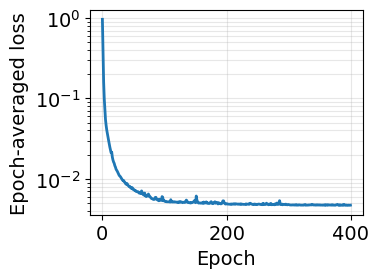

In [11]:
# plot the loss averaged over each epoch
plt.figure(figsize=(4, 3))
plt.plot(np.arange(Nepochs), loss_epoch_average, linewidth=2)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Epoch-averaged loss")
plt.yscale("log")
plt.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.savefig("LossEpochAverageBeta" + str(beta.numpy()) + ".pdf")

FaceCommittorBeta0.5.pdf


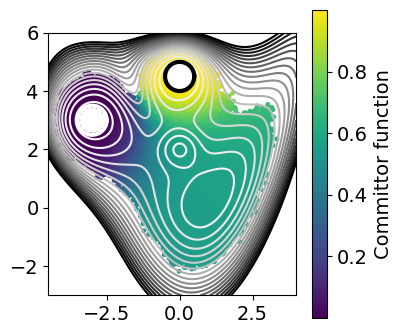

In [12]:
# visualize the computed committor
qmodel.eval()
with torch.no_grad():
    q_train_data = qmodel(train_data,a,b,ra,rb,ea,eb,fac).numpy().flatten()

# Create markers on the A and B boundaries
t=np.linspace(0,2*np.pi,100)
# ra is a Torch tensor with one element.
# ra.item() takes the single number stored in a one-element PyTorch tensor and 
# returns it as a plain Python number
Abdry_x = minimum_a[0] + ra.item()*np.cos(t)
Abdry_y = minimum_a[1] + ra.item()*np.sin(t)
Bbdry_x = minimum_b[0] + rb.item()*np.cos(t)
Bbdry_y = minimum_b[1] + rb.item()*np.sin(t)

plt.figure(figsize=(4,4))
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20),cmap = "Greys")
plt.scatter(xy_omegaAB[:,0],xy_omegaAB[:,1],s = 6, c = q_train_data,cmap = "viridis")
plt.plot(Abdry_x,Abdry_y,linewidth=3,color='white')
plt.plot(Bbdry_x,Bbdry_y,linewidth=3,color='black')
plt.colorbar(label="Committor function", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)
figname = "FaceCommittorBeta" + str(beta.numpy())+".pdf"
print(figname)
plt.savefig(figname)

In [13]:
# Check against the FEM solution
# fname = "FEM_face_output"+str(beta)
# np.savez(fname,pts = pts,tri = tri, q = q)
fname = "FEM_face_output"+str(beta.numpy())+".npz"
FEMdata = np.load(fname)
FEMpts = FEMdata['pts']
FEMtri = FEMdata['tri']
FEMq = FEMdata['q']

In [14]:
with torch.no_grad():
    NNq = qmodel(torch.from_numpy(FEMpts).float(),a,b,ra,rb,ea,eb,fac).numpy().flatten()
print(np.shape(FEMpts))
print(np.shape(FEMtri))
print(np.shape(NNq))

(4153, 2)
(8004, 3)
(4153,)


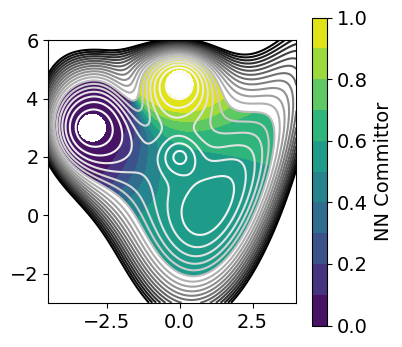

In [15]:
plt.figure(figsize=(4,4))
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20),cmap = "Greys")
plt.tricontourf(FEMpts[:,0], FEMpts[:,1],FEMtri,NNq,np.linspace(0,1,11))
plt.colorbar(label="NN Committor", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)

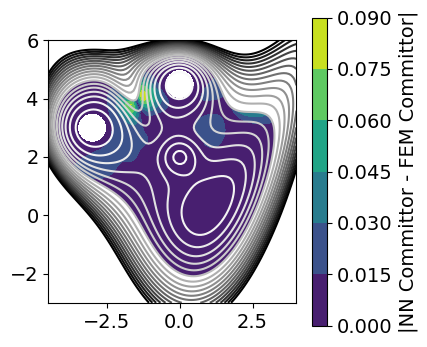

In [16]:
# plot error
plt.figure(figsize=(4,4))
ls = plt.contour(x_grid,y_grid,v_grid,range(0,20),cmap = "Greys")
plt.tricontourf(FEMpts[:,0], FEMpts[:,1],FEMtri,np.abs(NNq-FEMq))
plt.colorbar(label="|NN Committor - FEM Committor|", orientation="vertical")
axes=plt.gca()
axes.set_aspect(1)

In [17]:
# Compute the mean absolute error (MAE)
MAE = np.sum(np.abs(NNq-FEMq))/np.size(NNq)
print(f"MAE = {MAE:.3e}")
# Compute the root mean square error (RMSE)
RMSE = np.sqrt(np.mean((NNq-FEMq)**2))
print(f"RMSE = {RMSE:.3e}")
# Compute the weighted absolute error (WAE)
w = FEMq*(1-FEMq)*np.exp(-beta.numpy()*Vpot(FEMpts))
wsum = np.sum(w)
WAE = np.sum(w*np.abs(NNq-FEMq))/wsum
print(f"WAE = {WAE:.3e}")

# Without layer normalization:
# MAE = 1.057e-02
# RMSE = 1.640e-02
# WAE = 6.755e-03

MAE = 8.881e-03
RMSE = 1.370e-02
WAE = 6.134e-03
